**Unit 10 · Notebook 01**

# Follow a case through linked tables

**Learning objective:** Design linked case and laboratory tables.

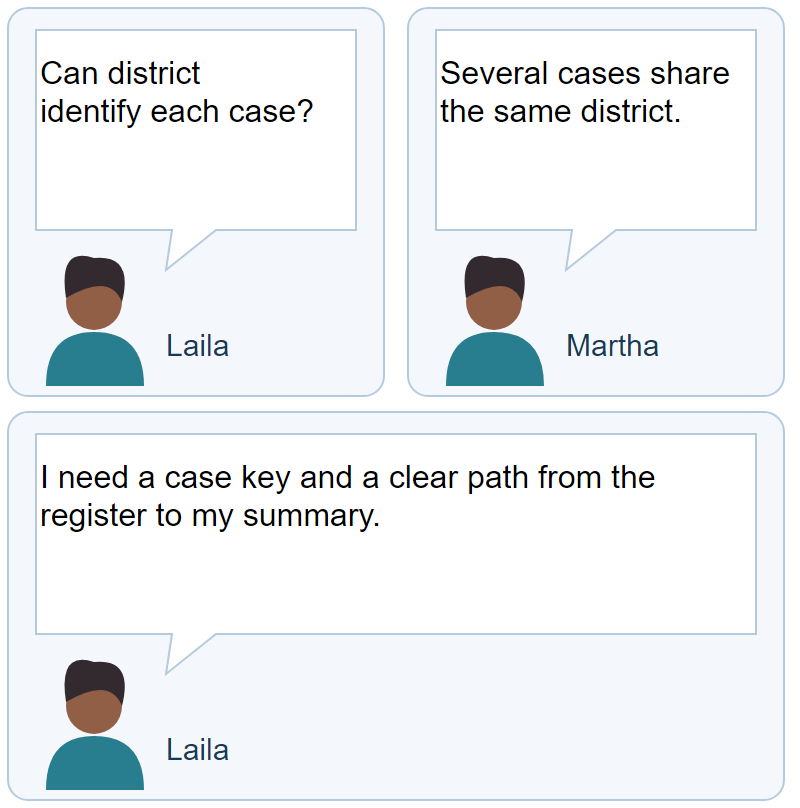

All records in this exercise are invented.

## Storage is a design decision
A primary key identifies a row uniquely. A foreign key connects a laboratory record to its case. A district name repeats and cannot identify a case. More than one laboratory record may refer to the same case; a laboratory table needs its own record identifier as well as `case_id`.

The course asks learners to map how data move through the HIS. Trace this pathway: **collection → district database → authorized analyst view → district summary**. A summary is an output, not a replacement for the event records. The browser DHIS2 adapter fits at the authorized-view boundary; this exercise stays in local tables.

Choose a case key, relationship, and flow. The key audit reveals what happens when a repeated field is treated as unique.

![Course health information system context](../../readings/ucsf/assets/his_context.png)

*Course health information system context.*


In [ ]:
# Run once to inspect the data and display the controls.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from IPython.display import display
from html import escape
from collections import Counter
from datetime import date
display(widgets.HTML("""<style>
.course-task-control { height: auto !important; margin-bottom: 0.75rem; gap: 0.25rem; }
.course-task-control > label { width: auto !important; text-align: left; white-space: normal; line-height: 1.4; }
.course-task-control > select, .course-task-control > input { width: 100% !important; min-width: 0; max-width: 100%; flex: 0 0 auto !important; }
</style>"""))

training_data = {'cases': [{'case_id': 'C01', 'district': 'Kambia', 'onset_date': '2021-10-18', 'age': 8, 'sex': 'F'}, {'case_id': 'C02', 'district': 'Kambia', 'onset_date': '2021-10-19', 'age': 12, 'sex': 'M'}, {'case_id': 'C03', 'district': 'Kambia', 'onset_date': '2021-10-20', 'age': 4, 'sex': 'F'}, {'case_id': 'C04', 'district': 'Port Loko', 'onset_date': '2021-10-20', 'age': 17, 'sex': 'M'}], 'lab': [{'case_id': 'C01', 'code': 'P'}, {'case_id': 'C02', 'code': 'PEND'}, {'case_id': 'C02', 'code': 'NEG'}, {'case_id': 'C99', 'code': 'X'}], 'code_map': {'P': 'positive', 'NEG': 'negative', 'PEND': 'pending'}, 'dictionary': [{'field': 'case_id', 'type': 'text', 'required': True, 'meaning': 'Stable case event identifier; preserve leading zeros'}, {'field': 'district', 'type': 'controlled text', 'required': True, 'meaning': 'Reporting district: Kambia or Port Loko'}, {'field': 'onset_date', 'type': 'ISO date', 'required': True, 'meaning': 'First symptom date; not specimen date'}, {'field': 'age', 'type': 'integer years', 'required': True, 'meaning': 'Completed years, 0 to 120'}], 'flows': [{'step': 1, 'location': 'Collection', 'output': 'Case event'}, {'step': 2, 'location': 'District database', 'output': 'Stored case_id'}, {'step': 3, 'location': 'Authorized analyst view', 'output': 'Scoped extract'}, {'step': 4, 'location': 'District summary', 'output': 'Aggregates for the briefing'}], 'age_cutoff': 5, 'draft_counts': {'district': 'Kambia', 'numerator': 3, 'denominator': 4}, 'population': None, 'causal_comparison': None, 'draft': [{'claim': 'counts', 'text': 'Three of four reported cases are from Kambia.'}, {'claim': 'risk', 'text': 'Kambia residents have three times the disease risk of Port Loko residents.'}, {'claim': 'cause', 'text': 'The reporting system caused the difference between districts.'}, {'claim': 'followup', 'text': 'Resolve the conflicting laboratory records before reporting final laboratory status.'}]}

def show_table(rows):
    if not rows:
        display(widgets.HTML("<p>No rows selected.</p>"))
        return
    names = list(rows[0])
    header = "".join("<th>" + escape(str(name)) + "</th>" for name in names)
    body = "".join("<tr>" + "".join("<td>" + escape(str(row.get(name, ""))) + "</td>" for name in names) + "</tr>" for row in rows)
    display(widgets.HTML('<div style="overflow-x:auto"><table><thead><tr>' + header + '</tr></thead><tbody>' + body + '</tbody></table></div>'))


def summarize(data):
    rows=data['cases']
    return {'district':dict(Counter(r['district'] for r in rows)),
            'onset':dict(sorted(Counter(r['onset_date'] for r in rows).items())),
            'age_group':dict(Counter('under5' if r['age']<data['age_cutoff'] else '5plus' for r in rows)),
            'sex':dict(Counter(r['sex'] for r in rows))}


def supported_claims(data):
    draft=data['draft_counts']
    counts=summarize(data)['district']
    lab_counts=Counter(r['case_id'] for r in data['lab'])
    supports={
        'counts': counts.get(draft['district'],0)==draft['numerator'] and len(data['cases'])==draft['denominator'],
        'risk': False,  # No population risk claim can follow from a report share alone.
        'cause': False, # No causal claim can follow from this descriptive case extract.
        'followup': any(v>1 for v in lab_counts.values())
    }
    return sorted(key for key,value in supports.items() if value)


def expected_answers(unit,data):
    if unit==9: return {'id_type':'text','pending':data['code_map']['PEND'],'unknown':'flag'}
    if unit==10: return {'key':'case_id','relationship':'one_many','flow':'collect_store_view_summary'}
    if unit==11: return {'boundary':data['age_cutoff'],'rows':len(data['cases']),'missing':'retain_unknown'}
    if unit==12:
        counts=Counter(r['case_id'] for r in data['lab'])
        return {'join':'left','conflicts':sum(v>1 for v in counts.values()),'unknown':'quarantine'}
    if unit==13:
        groups=summarize(data)['district']
        return {'kambia':groups.get('Kambia',0),'denominator':'reported_cases','chart':'onset','rate':'unavailable'}
    if unit==14:
        return {'supported':supported_claims(data),
                'risk':'needs_population','release':'human_review'}
    raise ValueError(unit)


def evaluate_answer(unit, response, data):
    expected = expected_answers(unit, data)
    if not isinstance(response, dict) or any(response.get(k) is None or response.get(k) == [] for k in expected):
        return "incomplete"
    for key, value in expected.items():
        actual = response.get(key)
        if isinstance(value, list):
            if not isinstance(actual, (list, tuple)) or sorted(actual) != sorted(value):
                return "incorrect"
        elif type(actual) is not type(value) or actual != value:
            return "incorrect"
    return "correct"


def build_artifact(unit,response,data):
    """Return inspectable outputs; leave original records untouched."""
    if unit==9:
        mapped=[{'source_code':r['code'],'value':data['code_map'].get(r['code']),
                 'action':'mapped' if r['code'] in data['code_map'] else ('review required' if response['unknown']=='flag' else 'UNSAFE: discarded unknown code')}
                for r in data['lab']]
        return {'Field dictionary':data['dictionary'],'Value reconciliation':mapped}
    if unit==10:
        keys=Counter(r[response['key']] for r in data['cases'])
        return {'Key audit':[{'candidate':response['key'],'distinct':len(keys),'rows':len(data['cases']),
                              'unique':all(v==1 for v in keys.values())}],
                'Record flow':data['flows'] if response['flow']=='collect_store_view_summary' else list(reversed(data['flows']))}
    if unit==11:
        output=[]
        for row in data['cases']:
            copy=dict(row)
            copy['age_group']='unknown' if row['age'] is None else ('under5' if row['age']<response['boundary'] else '5plus')
            output.append(copy)
        if response['missing']=='drop': output=[r for r in output if r['age_group']!='unknown']
        before=Counter(r['case_id'] for r in data['cases']);after=Counter(r['case_id'] for r in output)
        return {'Transformed copy':output,'Reconciliation':[{'input_rows':len(data['cases']),'output_rows':len(output),
                  'same_ID_multiplicity':before==after,'under5':sum(r['age_group']=='under5' for r in output)}]}
    if unit==12:
        index={}
        for row in data['lab']: index.setdefault(row['case_id'],[]).append(row)
        linked=[];review=[]
        for row in data['cases']:
            matches=index.get(row['case_id'],[])
            if not matches and response['join']=='inner': continue
            code=matches[0]['code'] if len(matches)==1 else None
            status='conflict' if len(matches)>1 else ('unmatched' if not matches else data['code_map'].get(code,'unmapped'))
            linked.append({**row,'result':status})
        case_ids={r['case_id'] for r in data['cases']}
        for row in data['lab']:
            errors=[]
            if row['case_id'] not in case_ids: errors.append('unknown case identifier')
            if len(index[row['case_id']])>1: errors.append('conflicting results; verify source')
            if row['code'] not in data['code_map']: errors.append('unmapped result code')
            review.append({**row,'accepted':not errors,'review':'; '.join(errors)})
        # Only resolved, mapped records enter the candidate exchange table. No network POST.
        payload=[{'case_id':r['case_id'],'result':data['code_map'][r['code']],'source':'training-lab'}
                 for r in data['lab'] if len(index[r['case_id']])==1 and r['case_id'] in case_ids and r['code'] in data['code_map']]
        return {'Linked case view':linked,'Import validation':review,'Candidate exchange rows':payload}
    if unit==13:
        summary=summarize(data);total=len(data['cases'])
        table=[{'district':k,'reported_cases':v,'share_of_reports':round(v/total,3) if total else None,'population_rate':'unavailable: no population denominator'} for k,v in summary['district'].items()]
        # Actual local chart, not an external plotting dependency.
        values=summary['onset'] if response['chart']=='onset' else summary['district']
        bars=''.join('<div>'+escape(str(k))+' <span style="display:inline-block;background:#287d8e;color:white;min-width:2em;width:'+str(v*45)+'px">'+str(v)+'</span></div>' for k,v in values.items())
        display(widgets.HTML('<h3>'+('Cases by onset date' if response['chart']=='onset' else 'Cases by district')+'</h3>'+bars+'<p>Invented reported cases; counts, not population risk.</p>'))
        return {'District briefing':table,'Person summary':[{'dimension':kind,'category':k,'count':v} for kind in ['age_group','sex'] for k,v in summary[kind].items()],
                'Time summary':[{'onset_date':k,'cases':v} for k,v in summary['onset'].items()]}
    if unit==14:
        total=len(data['cases']);counts=summarize(data)['district']
        return {'Draft review':[{'claim':r['text'],'your_decision':'supported' if r['claim'] in response['supported'] else 'not supported'} for r in data['draft']],
                'Evidence for the briefing':[{'measure':'Reported cases','value':total},
                     {'measure':'Kambia share of reports','value':counts.get('Kambia',0)/total if total else None},
                     {'measure':'Population denominator','value':'Not supplied'},
                     {'measure':'Causal comparison','value':'Not supplied'}]}
    raise ValueError(unit)

unit10_response = None
controls = {}
show_table(training_data['cases'])
show_table(training_data['flows'])
controls['key'] = widgets.Dropdown(description='Case table primary key', options=[('Select an answer', None), ('case_id', 'case_id'), ('district', 'district')], value=None, style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['key'].add_class('course-task-control')
display(controls['key'])
controls['relationship'] = widgets.Dropdown(description='Case to laboratory relationship', options=[('Select an answer', None), ('One case to many laboratory records', 'one_many'), ('One district to one case', 'one_one')], value=None, style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['relationship'].add_class('course-task-control')
display(controls['relationship'])
controls['flow'] = widgets.Dropdown(description='Data flow', options=[('Select an answer', None), ('Collect → store → authorized view → summary', 'collect_store_view_summary'), ('Summary → view → store → collect', 'reverse')], value=None, style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['flow'].add_class('course-task-control')
display(controls['flow'])


## Check my work

Run the next cell after making your choices. Revise and run again to retry. The Learning panel records incomplete and incorrect attempts as well as successful ones.

In [ ]:
# Check my work: run after making your choices above. Revise and run again to retry.
unit10_response = {key: (list(control.value) if isinstance(control, widgets.SelectMultiple)
                       else None if isinstance(control, widgets.BoundedIntText) and control.value < 0
                       else control.value) for key, control in controls.items()}
result = evaluate_answer(10, unit10_response, training_data)
if result == "incomplete":
    print("Incomplete: answer every field, then check again.")
else:
    artifact = build_artifact(10, unit10_response, training_data)
    if isinstance(artifact, dict):
        for title, rows in artifact.items():
            print(title)
            show_table(rows)
    else:
        show_table(artifact)
    print("Correct: your result follows the stated evidence and training rules." if result == "correct"
          else "Not yet correct: compare the artifact with the task and rules. Revise your choices and retry; the Learning panel offers hints.")


## Reflect on the decision

Run the next cell. Write your reflections, then select **Record** to save them with your learner record in this browser. Reflections are unscored.

In [ ]:
# Run this cell to write and record your reflections.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from html import escape
from IPython.display import display
from comm import create_comm

def _reflection_section(section, prompts):
    fields = []
    for number, prompt in enumerate(prompts, 1):
        field = widgets.Textarea(placeholder="Write your reflection here", rows=5,
                                 layout=widgets.Layout(width="100%"))
        fields.append(field)
        display(widgets.VBox([
            widgets.HTML(value=f"<strong>{number}. {escape(prompt)}</strong>"), field
        ], layout=widgets.Layout(width="100%", padding="0.5rem", margin="0 0 0.5rem 0")))
    button = widgets.Button(description="Record", button_style="info", disabled=True)
    status = widgets.HTML(value="Connecting to your browser learner record...")
    channel = create_comm(target_name="al.reflections", data={"section": section})
    def receive(message):
        data = message["content"]["data"]
        if "entries" in data:
            saved = {entry["prompt"]: entry["answer"] for entry in data["entries"]}
            for prompt, field in zip(prompts, fields):
                field.value = saved.get(prompt, "")
            status.value = "Recorded reflections restored." if saved else "Select Record to save in this browser."
        elif data.get("saved"):
            status.value = "Recorded in this browser. Your reflections are unscored."
        else:
            status.value = escape(data.get("error", "Could not record. Please try again."))
        button.disabled = False
    channel.on_msg(receive)
    def record(_):
        button.disabled = True
        status.value = "Recording..."
        channel.send({"entries": [{"prompt": prompt, "answer": field.value}
                                  for prompt, field in zip(prompts, fields)]})
    def edited(_):
        status.value = "Changes not recorded. Select Record to save."
    for field in fields:
        field.observe(edited, names="value")
    button.on_click(record)
    display(button, status)

_reflection_section('exercise:u10-table-design-data-flow', ['Where could a delayed report change the district summary?', 'Why should laboratory records have their own identifier as well as case_id?'])


## Continue learning

[Next notebook](u11-n01-recode-reconcile.ipynb) · [Course start](u00-n00-start-here.ipynb)

Review attempts, hints, and recommendations in the **Learning** panel.

## References

- Public Health Informatics for FETP, Version 2 Unit 5 storage and data-flow sections; UCSF Unit 10 topic wrapper and Unit 5 Assignment 2 (data transmission map).
- [Unit 2 course slides (local PDF)](../../readings/ucsf/assets/unit-2-version-2-slides.pdf).
